In [1]:
# %%
import os
import sys
import cv2
import json
import torch
import numpy as np
import onnxruntime as ort
import matplotlib.pyplot as plt
import time

# Configuration affichage
%matplotlib inline

# Ajout du dossier courant au path pour trouver 'lib' si nécessaire
sys.path.append(os.getcwd())

In [2]:


class DatasetImage:
    def __init__(self, img_path, model_path=None):
        """
        Initialise l'objet DatasetImage.
        
        Args:
            img_path (str): Chemin vers l'image source.
            model_path (str, optional): Chemin vers le modèle ONNX. Requis pour l'inférence.
        """
        self.img_path = img_path
        self.model_path = model_path
        
        if not os.path.exists(self.img_path):
            raise FileNotFoundError(f"Image introuvable : {self.img_path}")
            
        # Chargement initial de l'image
        self.img_bgr = cv2.imread(self.img_path)
        self.img_rgb = cv2.cvtColor(self.img_bgr, cv2.COLOR_BGR2RGB)
        self.h_orig, self.w_orig = self.img_rgb.shape[:2]
        
        # Chemins GT
        self.da_path, self.ll_path, self.det_path = self._get_gt_paths()
        
        # Session ONNX (Lazy loading : sera initialisé au besoin ou par méthode explicite)
        self.session = None
        
        # Résultats (caches)
        self.pred_da = None
        self.pred_ll = None
        self.pred_boxes = None
        self.gt_da = None
        self.gt_ll = None
        self.gt_boxes = None
        self.inference_time = 0

    def _get_gt_paths(self):
        """Détermine les chemins des vérités terrain (GT) basés sur le nom de l'image."""
        da_path = self.img_path.replace("images", "da_seg_annotations").replace(".jpg", ".png")
        ll_path = self.img_path.replace("images", "ll_seg_annotations").replace(".jpg", ".png")
        det_path = self.img_path.replace("images", "det_annotations").replace(".jpg", ".json")
        return da_path, ll_path, det_path

    def _resize_unscale(self, img, new_shape=(640, 640), color=114):
        """Redimensionne l'image avec padding (Letterbox)."""
        shape = img.shape[:2]
        if isinstance(new_shape, int): new_shape = (new_shape, new_shape)

        r = min(new_shape[0] / shape[0], new_shape[1] / shape[1])
        new_unpad = int(round(shape[1] * r)), int(round(shape[0] * r))
        dw, dh = new_shape[1] - new_unpad[0], new_shape[0] - new_unpad[1]
        dw, dh = dw // 2, dh // 2

        if shape[::-1] != new_unpad:
            img = cv2.resize(img, new_unpad, interpolation=cv2.INTER_AREA)

        canvas = np.full((new_shape[0], new_shape[1], 3), color, dtype=np.uint8)
        canvas[dh:dh + new_unpad[1], dw:dw + new_unpad[0], :] = img

        return canvas, r, dw, dh, new_unpad[0], new_unpad[1]

    def load_ground_truth(self):
        """Charge les masques et les boîtes de vérité terrain."""
        # 1. Masques
        if os.path.exists(self.da_path):
            self.gt_da = cv2.imread(self.da_path, cv2.IMREAD_GRAYSCALE)
            if self.gt_da.shape != (self.h_orig, self.w_orig):
                self.gt_da = cv2.resize(self.gt_da, (self.w_orig, self.h_orig), interpolation=cv2.INTER_NEAREST)
        
        if os.path.exists(self.ll_path):
            self.gt_ll = cv2.imread(self.ll_path, cv2.IMREAD_GRAYSCALE)
            if self.gt_ll.shape != (self.h_orig, self.w_orig):
                self.gt_ll = cv2.resize(self.gt_ll, (self.w_orig, self.h_orig), interpolation=cv2.INTER_NEAREST)

        # 2. Boîtes (JSON)
        self.gt_boxes = []
        if os.path.exists(self.det_path):
            try:
                with open(self.det_path, 'r') as f:
                    data = json.load(f)
                frames = data.get('frames', [])
                if frames:
                    objects = frames[0].get('objects', [])
                    for obj in objects:
                        if obj.get('category') in ['car', 'bus', 'truck', 'train']:
                            box2d = obj.get('box2d', {})
                            if box2d:
                                self.gt_boxes.append([
                                    float(box2d['x1']), float(box2d['y1']),
                                    float(box2d['x2']), float(box2d['y2'])
                                ])
            except Exception as e:
                print(f"Erreur lecture JSON {self.det_path}: {e}")
        self.gt_boxes = np.array(self.gt_boxes)

    def run_inference(self):
        """Exécute l'inférence ONNX et post-traite les résultats."""
        if not self.model_path or not os.path.exists(self.model_path):
            raise FileNotFoundError("Modèle ONNX introuvable.")
        
        if self.session is None:
            self.session = ort.InferenceSession(self.model_path)

        # Preprocess
        img_resized, r, dw, dh, nw, nh = self._resize_unscale(self.img_rgb, (640, 640))
        
        # 2. Normalisation (Reproduction exacte de transforms.Normalize)
        img_input = img_resized.astype(np.float32) / 255.0
        img_input = (img_input - [0.485, 0.456, 0.406]) / [0.229, 0.224, 0.225]
        img_input = img_input.transpose(2, 0, 1)[None].astype(np.float32)

        # Inference Time Measurement
        start_time = time.time()
        outputs = self.session.run(['det_out', 'drive_area_seg', 'lane_line_seg'], 
                                   {self.session.get_inputs()[0].name: img_input})
        self.inference_time = (time.time() - start_time) * 1000 # ms
        
        det_out, da_seg_out, ll_seg_out = outputs

        # Post-process Segmentation
        da_mask = np.argmax(da_seg_out[:, :, dh:dh+nh, dw:dw+nw], axis=1)[0]
        ll_mask = np.argmax(ll_seg_out[:, :, dh:dh+nh, dw:dw+nw], axis=1)[0]
        
        self.pred_da = cv2.resize(da_mask.astype(np.uint8), (self.w_orig, self.h_orig), interpolation=cv2.INTER_NEAREST)
        self.pred_ll = cv2.resize(ll_mask.astype(np.uint8), (self.w_orig, self.h_orig), interpolation=cv2.INTER_NEAREST)

        # Post-process Détection (NMS)
        self.pred_boxes = []
        try:
            # Essai d'import local de la lib YOLOP
            from lib.core.general import non_max_suppression
            det_tensor = torch.from_numpy(det_out).float()
            nms_out = non_max_suppression(det_tensor, 0.25, 0.45)[0]
            if nms_out is not None and len(nms_out) > 0:
                nms_out = nms_out.cpu().numpy()
                nms_out[:, 0] -= dw
                nms_out[:, 1] -= dh
                nms_out[:, 2] -= dw
                nms_out[:, 3] -= dh
                nms_out[:, :4] /= r
                self.pred_boxes = nms_out
        except ImportError:
            print("NMS non disponible (lib.core.general manquant).")

    # ==========================================
    # MÉTHODES POUR LE CALCUL DES KPI (DATA COLLECTORS)
    # ==========================================
    
    def get_speed_kpi(self):
        """Retourne le temps d'inférence pour cette image."""
        return self.inference_time

    def get_segmentation_stats(self, type='da'):
        """
        Retourne les stats brutes (Intersection, Union) pour le calcul de mIoU sur N images.
        Args:
            type (str): 'da' (Drivable Area) ou 'll' (Lane Line)
        Returns:
            dict: { 'intersection': int, 'union': int, 'area_pred': int, 'area_gt': int }
        """
        if type == 'da':
            pred = self.pred_da
            gt = self.gt_da
        else:
            pred = self.pred_ll
            gt = self.gt_ll

        if pred is None or gt is None:
            return {'intersection': 0, 'union': 0, 'area_pred': 0, 'area_gt': 0}

        # Binarisation stricte (>0 devient 1)
        pred_bin = (pred > 0).astype(np.uint8)
        gt_bin = (gt > 0).astype(np.uint8)

        intersection = np.logical_and(pred_bin, gt_bin).sum()
        union = np.logical_or(pred_bin, gt_bin).sum()
        
        return {
            'intersection': int(intersection),
            'union': int(union),
            'area_pred': int(pred_bin.sum()),
            'area_gt': int(gt_bin.sum())
        }

# ==========================================
    # MODIFICATION CHIRURGICALE : DatasetImage
    # ==========================================
    def get_detection_stats(self, iou_threshold=0.5):
        """
        Retourne la liste détaillée des prédictions pour le calcul mAP global.
        Returns:
            dict: {
                'pred_details': list of [confidence, is_tp], 
                'gt_count': int
            }
        """
        if self.pred_boxes is None: self.pred_boxes = []
        if self.gt_boxes is None: self.gt_boxes = []

        gt_count = len(self.gt_boxes)
        pred_details = [] # Liste de [score, is_tp]

        # S'il n'y a pas de prédictions, on renvoie vide
        if len(self.pred_boxes) == 0:
            return {'pred_details': [], 'gt_count': gt_count}

        # On suppose que pred_boxes contient [x1, y1, x2, y2, conf, cls]
        # On trie par confiance décroissante
        preds = sorted(self.pred_boxes, key=lambda x: x[4], reverse=True)
        
        # Pour éviter de matcher plusieurs fois la même GT
        matched_gt_indices = set()

        for pred in preds:
            bbox_pred = pred[:4]
            conf = pred[4]
            best_iou = 0
            best_gt_idx = -1

            # On cherche la meilleure GT pour cette prédiction
            for idx, gt in enumerate(self.gt_boxes):
                if idx in matched_gt_indices: continue # Déjà trouvée
                
                # Calcul IoU
                xA = max(bbox_pred[0], gt[0])
                yA = max(bbox_pred[1], gt[1])
                xB = min(bbox_pred[2], gt[2])
                yB = min(bbox_pred[3], gt[3])
                interArea = max(0, xB - xA) * max(0, yB - yA)
                boxAArea = (bbox_pred[2] - bbox_pred[0]) * (bbox_pred[3] - bbox_pred[1])
                boxBArea = (gt[2] - gt[0]) * (gt[3] - gt[1])
                iou = interArea / float(boxAArea + boxBArea - interArea + 1e-6)

                if iou > best_iou:
                    best_iou = iou
                    best_gt_idx = idx
            
            # Si IoU suffisant et GT pas encore matchée -> Vrai Positif (TP)
            if best_iou >= iou_threshold and best_gt_idx != -1:
                pred_details.append([conf, True]) # [Confiance, C'est un TP]
                matched_gt_indices.add(best_gt_idx)
            else:
                pred_details.append([conf, False]) # [Confiance, C'est un FP]
        
        return {
            'pred_details': pred_details,
            'gt_count': gt_count
        }

    # ==========================================
    # MÉTHODES DE VISUALISATION
    # ==========================================
    def visualize(self):
        """Affiche une comparaison Prédiction vs Réalité."""
        def draw(img, da, ll, boxes, color_box):
            res = img.copy()
            # Seg
            color_seg = np.zeros_like(res)
            if da is not None: color_seg[da > 0] = [0, 255, 0]
            if ll is not None: color_seg[ll > 0] = [255, 0, 0]
            mask_ind = np.any(color_seg != 0, axis=-1)
            res[mask_ind] = res[mask_ind] * 0.6 + color_seg[mask_ind] * 0.4
            # Box
            if boxes is not None and len(boxes) > 0:
                for box in boxes:
                    x1, y1, x2, y2 = map(int, box[:4])
                    cv2.rectangle(res, (x1, y1), (x2, y2), color_box, 2)
            return res

        viz_pred = draw(self.img_rgb, self.pred_da, self.pred_ll, self.pred_boxes, (0, 140, 255))
        viz_gt = draw(self.img_rgb, self.gt_da, self.gt_ll, self.gt_boxes, (255, 255, 0))

        plt.figure(figsize=(24, 12))
        plt.subplot(1, 2, 1); plt.imshow(viz_pred); plt.title(f"PRÉDICTION ({self.inference_time:.1f}ms)"); plt.axis('off')
        plt.subplot(1, 2, 2); plt.imshow(viz_gt); plt.title("RÉALITÉ TERRAIN"); plt.axis('off')
        plt.tight_layout(); plt.show()



In [3]:
# %%
from tqdm import tqdm # Pour la barre de progression

class DatasetFull:
    def __init__(self, img_dir, model_path, max_images=100):
        """
        Gère l'évaluation sur un ensemble d'images.
        """
        self.img_dir = img_dir
        self.model_path = model_path
        self.max_images = max_images
        
        # Liste des fichiers images
        self.image_files = sorted([f for f in os.listdir(img_dir) if f.endswith('.jpg')])
        if max_images is not None:
            self.image_files = self.image_files[:max_images]
            
        print(f"📂 Dataset initialisé : {len(self.image_files)} images à traiter.")

        # --- Stockage des Stats Globales ---
        # Speed
        self.inference_times = []
        
        # Segmentation (mIoU)
        self.da_inter_sum = 0
        self.da_union_sum = 0
        self.ll_inter_sum = 0
        self.ll_union_sum = 0
        
        # Détection (mAP)
        # Liste globale de [confiance, is_tp] pour toutes les images
        self.all_det_predictions = [] 
        self.total_gt_boxes = 0

    def process_all(self):
        """Lance l'inférence sur toutes les images."""
        print("🚀 Démarrage de l'évaluation...")
        
        for img_name in tqdm(self.image_files):
            img_path = os.path.join(self.img_dir, img_name)
            
            try:
                # 1. Instanciation de l'image unique
                img_obj = DatasetImage(img_path, self.model_path)
                
                # 2. Chargement GT et Inférence
                img_obj.load_ground_truth()
                img_obj.run_inference()
                
                # 3. Collecte Speed
                self.inference_times.append(img_obj.get_speed_kpi())
                
                # 4. Collecte Segmentation (Driving Area)
                da_stats = img_obj.get_segmentation_stats('da')
                self.da_inter_sum += da_stats['intersection']
                self.da_union_sum += da_stats['union']
                
                # 5. Collecte Segmentation (Lane Line)
                ll_stats = img_obj.get_segmentation_stats('ll')
                self.ll_inter_sum += ll_stats['intersection']
                self.ll_union_sum += ll_stats['union']
                
                # 6. Collecte Détection (Pour mAP)
                det_stats = img_obj.get_detection_stats(iou_threshold=0.5)
                self.all_det_predictions.extend(det_stats['pred_details'])
                self.total_gt_boxes += det_stats['gt_count']
                
            except Exception as e:
                print(f"❌ Erreur sur {img_name}: {e}")

    def compute_metrics(self):
        """Calcule et affiche tous les KPI finaux."""
        print("\n" + "="*40)
        print("📊 RÉSULTATS GLOBAUX DU DATASET")
        print("="*40)
        
        # --- 1. SPEED ---
        if self.inference_times:
            avg_time = np.mean(self.inference_times)
            fps = 1000 / avg_time if avg_time > 0 else 0
            print(f"⏱️  Vitesse Moyenne : {avg_time:.2f} ms/frame ({fps:.1f} FPS)")
        
        # --- 2. SEGMENTATION (Global mIoU) ---
        # mIoU = Intersection Totale / Union Totale (Plus robuste que la moyenne des IoU)
        da_iou = (self.da_inter_sum / self.da_union_sum) if self.da_union_sum > 0 else 0
        ll_iou = (self.ll_inter_sum / self.ll_union_sum) if self.ll_union_sum > 0 else 0
        
        print("-" * 40)
        print("🛣️  SEGMENTATION")
        print(f"   - Driving Area mIoU : {da_iou:.2%}")
        print(f"   - Lane Line mIoU    : {ll_iou:.2%}")

        # --- 3. DÉTECTION (Recall & AP) ---
        print("-" * 40)
        print("🚗 DÉTECTION (Traffic Objects)")
        
        if self.total_gt_boxes == 0:
            print("   - Pas de vérité terrain (GT) trouvée pour les voitures.")
            return

        # Tri de toutes les prédictions du dataset par confiance décroissante
        # all_det_predictions est une liste de [conf, is_tp]
        # ... (début inchangé) ...

        # --- CORRECTION 4 : Calcul mAP plus robuste (Style VOC/COCO) ---
        # On utilise une méthode d'intégration plus précise pour l'AP
        
        # Tri décroissant par confiance
        preds = sorted(self.all_det_predictions, key=lambda x: x[0], reverse=True)
        
        tp_list = [p[1] for p in preds]
        tp_cumsum = np.cumsum(tp_list)
        fp_cumsum = np.cumsum([not x for x in tp_list])
        
        # Ajout d'epsilon pour éviter division par zéro
        recalls = tp_cumsum / (self.total_gt_boxes + 1e-16)
        precisions = tp_cumsum / (tp_cumsum + fp_cumsum + 1e-16)
        
        # Méthode AP : Intégration continue (Continuous Integration)
        # On ajoute les points sentinelles (0,0) et (1,0) pour fermer la courbe
        mrec = np.concatenate(([0.0], recalls, [1.0]))
        mpre = np.concatenate(([1.0], precisions, [0.0])) # Precision commence à 1

        # On lisse la courbe de précision (elle doit être monotone décroissante)
        for i in range(mpre.size - 1, 0, -1):
            mpre[i - 1] = np.maximum(mpre[i - 1], mpre[i])

        # Calcul de l'aire sous la courbe (AUC)
        i = np.where(mrec[1:] != mrec[:-1])[0]
        ap = np.sum((mrec[i + 1] - mrec[i]) * mpre[i + 1])

        # Recall Final
        final_recall = recalls[-1] if len(recalls) > 0 else 0

        print(f"   - Nombre d'objets GT  : {self.total_gt_boxes}")
        print(f"   - Nombre de détections: {len(preds)}")
        print(f"   - Recall Global       : {final_recall:.2%}")
        print(f"   - mAP@50 (Approx)     : {ap:.2%}")
        print("="*40)



Stats DA pour cette image : {'intersection': 200448, 'union': 211761, 'area_pred': 209624, 'area_gt': 202585}
Stats Det pour cette image : {'pred_details': [[0.91533875, True], [0.9058969, True], [0.8763828, True], [0.86735666, True], [0.8288265, True], [0.82720965, True], [0.819551, True], [0.8099822, True], [0.79304343, True], [0.7450232, True], [0.6607942, True], [0.6562685, True], [0.63175166, True], [0.6229728, False], [0.56538934, True], [0.53467053, True], [0.5099983, False], [0.5075947, True], [0.49073997, False], [0.47974706, False], [0.45255142, False], [0.42348313, True], [0.4098252, False], [0.39145502, False], [0.35079116, False], [0.32211325, False], [0.25922987, False]], 'gt_count': 19}
Vitesse : 96.53 ms


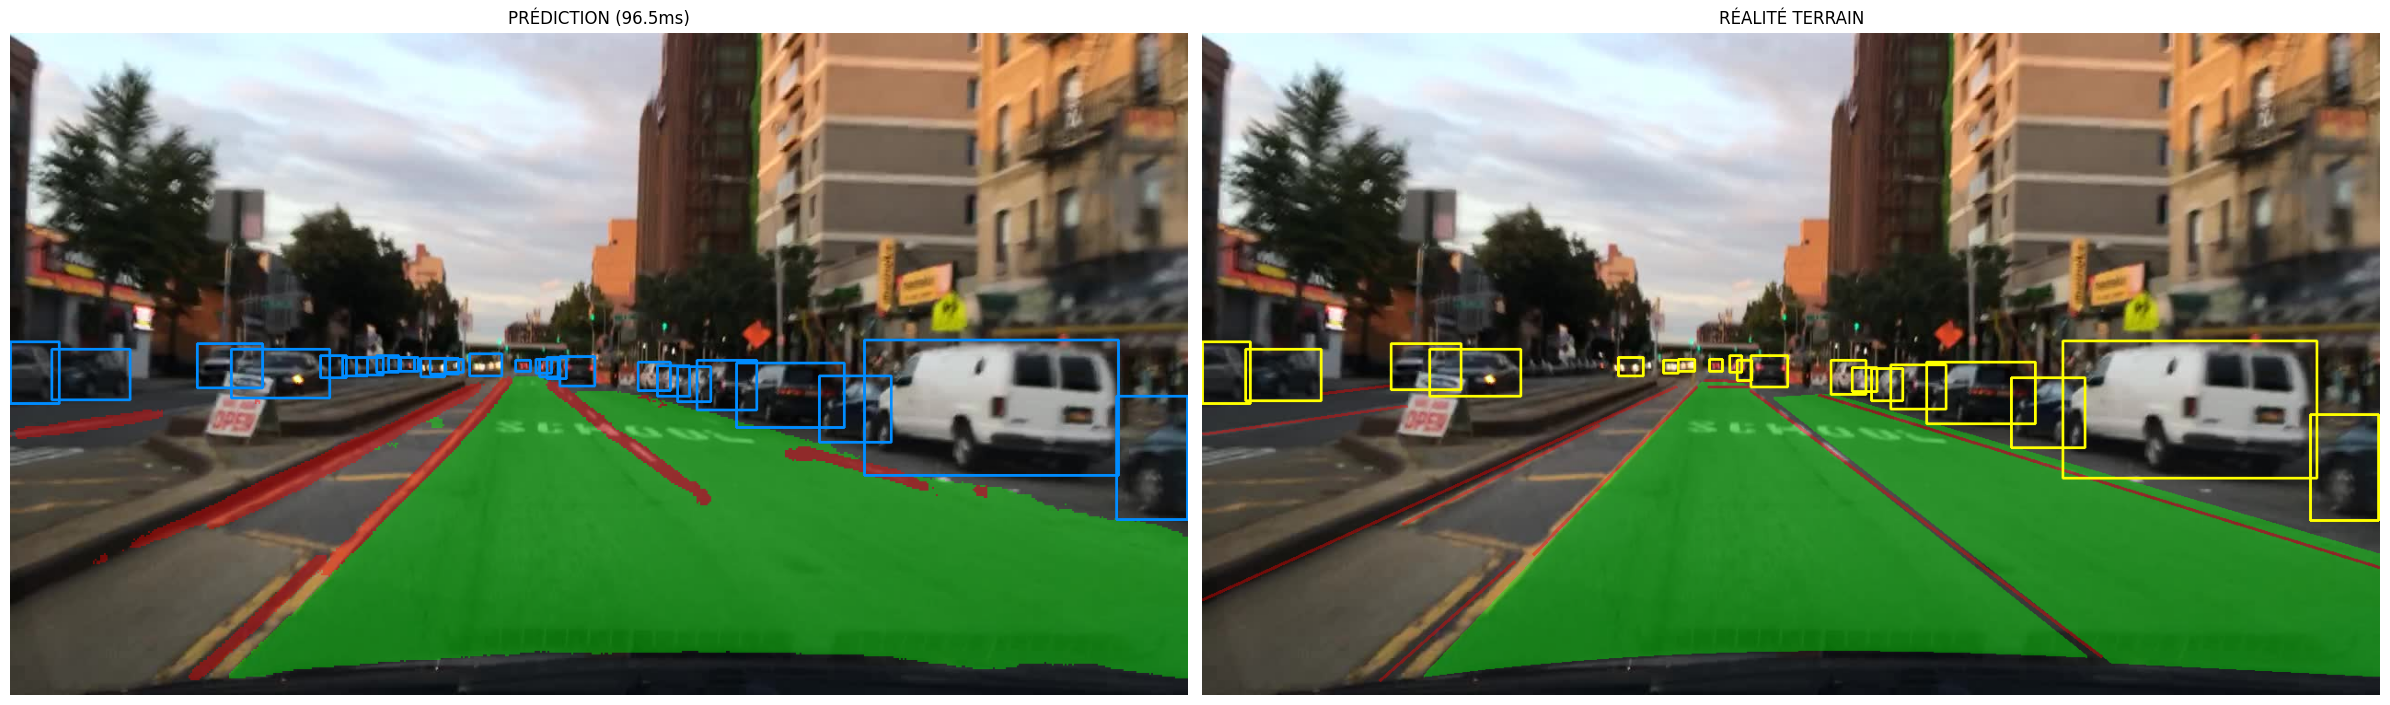

In [4]:
# ==========================================
# EXEMPLE D'UTILISATION
# ==========================================
if __name__ == "__main__":
    # Chemins à adapter
    WEIGHT_PATH = "weights/yolop-640-640.onnx"
    IMG_PATH = "dataset/images/val/b1c66a42-6f7d68ca.jpg"

    try:
        # 1. Création de l'objet
        image_obj = DatasetImage(IMG_PATH, WEIGHT_PATH)
        
        # 2. Chargement GT et Inférence
        image_obj.load_ground_truth()
        image_obj.run_inference()
        
        # 3. Récupération des données KPI (pour usage externe)
        da_stats = image_obj.get_segmentation_stats('da')
        det_stats = image_obj.get_detection_stats()
        speed = image_obj.get_speed_kpi()
        
        print(f"Stats DA pour cette image : {da_stats}")
        print(f"Stats Det pour cette image : {det_stats}")
        print(f"Vitesse : {speed:.2f} ms")

        # 4. Visualisation
        image_obj.visualize()

    except Exception as e:
        print(f"Erreur : {e}")

In [5]:
# ==========================================
# EXEMPLE D'UTILISATION
# ==========================================
if __name__ == "__main__":
    # Paramètres
    VAL_DIR = "dataset/images/val"
    ONNX_PATH = "weights/yolop-640-640.onnx"
    
    # Création et Lancement
    # On teste sur 100 images
    dataset_eval = DatasetFull(VAL_DIR, ONNX_PATH, max_images=100)
    
    # 1. Traitement
    dataset_eval.process_all()
    
    # 2. Affichage des KPI
    dataset_eval.compute_metrics()

📂 Dataset initialisé : 100 images à traiter.
🚀 Démarrage de l'évaluation...


100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 100/100 [00:21<00:00,  4.73it/s]



📊 RÉSULTATS GLOBAUX DU DATASET
⏱️  Vitesse Moyenne : 101.50 ms/frame (9.9 FPS)
----------------------------------------
🛣️  SEGMENTATION
   - Driving Area mIoU : 84.86%
   - Lane Line mIoU    : 20.63%
----------------------------------------
🚗 DÉTECTION (Traffic Objects)
   - Nombre d'objets GT  : 1057
   - Nombre de détections: 1042
   - Recall Global       : 72.75%
   - mAP@50 (Approx)     : 70.19%
